# X-Ray Projections

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch08/ch08-03.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Parallel Projections

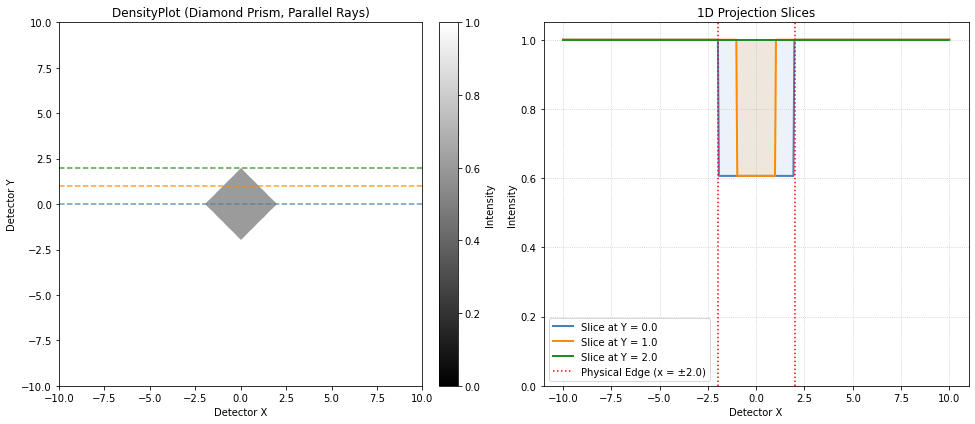

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Parameters ---
shape = 'diamond'  # Options: 'square', 'circle', 'diamond', 'plus', 'diagonal'

w = 4.0     # Width of the shape
L = 2.0     # Thickness of the prism along Z
a = 1.0     # Arm thickness for 'plus' and 'diagonal' shapes
mu_a = 0.25

# --- 2. Setup the Grid ---
N = 400
x = np.linspace(-10, 10, N)
y = np.linspace(-10, 10, N)
xx, yy = np.meshgrid(x, y)

# --- 3. Exact Mathematical Calculations (Parallel Rays) ---
# For parallel rays, there is no inverse square falloff and no obliquity.
I0 = 1.0

# Determine which pixels fall inside the exact 2D footprint of the extruded shape
if shape == 'square':
    mask = (np.abs(xx) <= w/2) & (np.abs(yy) <= w/2)

elif shape == 'circle':
    mask = (xx**2 + yy**2) <= (w/2)**2

elif shape == 'diamond':
    mask = (np.abs(xx) + np.abs(yy)) <= w/2

elif shape == 'plus':
    mask = ((np.abs(xx) <= w/2) & (np.abs(yy) <= a/2)) | \
           ((np.abs(xx) <= a/2) & (np.abs(yy) <= w/2))

elif shape == 'diagonal':
    # Rotate coordinates by 45 degrees
    xp = (xx - yy) / np.sqrt(2)
    yp = (xx + yy) / np.sqrt(2)
    mask = ((np.abs(xp) <= w/2) & (np.abs(yp) <= a/2)) | \
           ((np.abs(xp) <= a/2) & (np.abs(yp) <= w/2))

else:
    raise ValueError("Invalid shape selected.")

# With parallel rays along Z, the ray travels exactly distance L through the object
L_eff = np.where(mask, L, 0.0)

# Final Intensity function
Id = I0 * np.exp(-mu_a * L_eff)


# --- 4. Plotting ---
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: 2D Radiograph
im = axes1[0].imshow(
    Id, extent=[-10, 10, -10, 10], origin='lower', cmap='gray', vmin=0, vmax=1
)
axes1[0].set_title(f'DensityPlot ({shape.capitalize()} Prism, Parallel Rays)')
axes1[0].set_xlabel('Detector X')
axes1[0].set_ylabel('Detector Y')
fig1.colorbar(im, ax=axes1[0], fraction=0.046, pad=0.04, label='Intensity')

# Define three Y-slices to visualize the shape narrowing
y_slices = [0.0, 1.0, 2.0]
colors = ['steelblue', 'darkorange', 'forestgreen']

for y_val, color in zip(y_slices, colors):
    axes1[0].axhline(y_val, color=color, linestyle='--', alpha=0.8)

# Plot 2: Multiple 1D Slices
for y_val, color in zip(y_slices, colors):
    y_idx = np.argmin(np.abs(y - y_val)) 
    
    axes1[1].plot(x, Id[y_idx, :], color=color, linewidth=2, label=f'Slice at Y = {y_val}')
    axes1[1].fill_between(x, Id[y_idx, :], 1.0, color=color, alpha=0.1)

axes1[1].set_title(f'1D Projection Slices')
axes1[1].set_xlabel('Detector X')
axes1[1].set_ylabel('Intensity')
axes1[1].set_ylim([0, 1.05])
axes1[1].grid(True, linestyle=':', alpha=0.7)

# Show the exact physical boundary for y=0 to prove there is no magnification
bound = w/2
axes1[1].axvline(bound, color='red', linestyle=':', label=f'Physical Edge (x = ±{bound})')
axes1[1].axvline(-bound, color='red', linestyle=':')

axes1[1].legend()

plt.tight_layout()
plt.show()

## Radial Projections

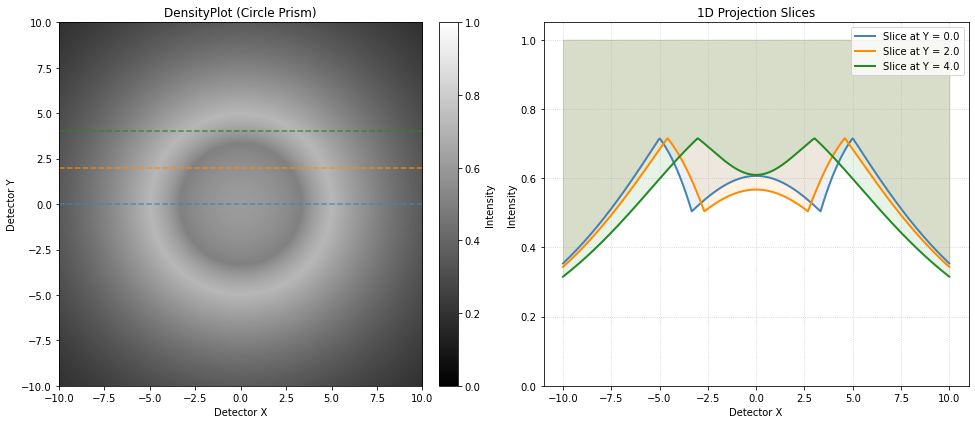

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# --- 1. Parameters ---
shape2 = 'circle'  # Try changing this back to 'square' to compare!

d = 10.0
z0 = 5.0
w2 = 4.0
L2 = 2.0
a2 = 1.0     
mu_a2 = 0.25

# --- 2. Setup the Grid ---
N2 = 400
x2 = np.linspace(-10, 10, N2)
y2 = np.linspace(-10, 10, N2)
xx2, yy2 = np.meshgrid(x2, y2)

# --- 3. Exact Mathematical Calculations ---
r = np.sqrt(xx2**2 + yy2**2 + d**2)
I0_2 = (d / r)**3

tzmin = (z0 - L2/2) / d
tzmax = (z0 + L2/2) / d

xx_safe = np.maximum(np.abs(xx2), 1e-9)
yy_safe = np.maximum(np.abs(yy2), 1e-9)

if shape2 == 'square':
    t_xy_max = np.minimum((w2/2) / xx_safe, (w2/2) / yy_safe)
elif shape2 == 'circle':
    t_xy_max = (w2/2) / np.sqrt(xx2**2 + yy2**2 + 1e-9)
elif shape2 == 'diamond':
    t_xy_max = (w2/2) / (xx_safe + yy_safe)
elif shape2 == 'plus':
    t_H = np.minimum((w2/2) / xx_safe, (a2/2) / yy_safe)  
    t_V = np.minimum((a2/2) / xx_safe, (w2/2) / yy_safe)  
    t_xy_max = np.maximum(t_H, t_V)                     
elif shape2 == 'diagonal':
    xp_safe = np.maximum(np.abs(xx2 - yy2) / np.sqrt(2), 1e-9)
    yp_safe = np.maximum(np.abs(xx2 + yy2) / np.sqrt(2), 1e-9)
    t_H = np.minimum((w2/2) / xp_safe, (a2/2) / yp_safe)
    t_V = np.minimum((a2/2) / xp_safe, (w2/2) / yp_safe)
    t_xy_max = np.maximum(t_H, t_V)
else:
    raise ValueError("Invalid shape selected.")

tin = np.full_like(xx2, tzmin)
tout = np.minimum(t_xy_max, tzmax)

hit = (tin < tout) & (tout > 0)
delta_t = np.where(hit, tout - tin, 0)
L_eff2 = delta_t * r

Id2 = I0_2 * np.exp(-mu_a2 * L_eff2)


# --- 4. Plotting ---
fig2, axes2 = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: 2D Radiograph
im2 = axes2[0].imshow(
    Id2, extent=[-10, 10, -10, 10], origin='lower', cmap='gray', vmin=0, vmax=1
)
axes2[0].set_title(f'DensityPlot ({shape2.capitalize()} Prism)')
axes2[0].set_xlabel('Detector X')
axes2[0].set_ylabel('Detector Y')
fig2.colorbar(im2, ax=axes2[0], fraction=0.046, pad=0.04, label='Intensity')

# Define the three Y-slices we want to look at
y_slices2 = [0.0, 2.0, 4.0]
colors2 = ['steelblue', 'darkorange', 'forestgreen']

# Draw horizontal lines on the 2D image to show where we are slicing
for y_val, color in zip(y_slices2, colors2):
    axes2[0].axhline(y_val, color=color, linestyle='--', alpha=0.8)

# Plot 2: Multiple 1D Slices
for y_val, color in zip(y_slices2, colors2):
    # Find the closest array index to our target y_val
    y_idx2 = np.argmin(np.abs(y2 - y_val)) 
    
    axes2[1].plot(x2, Id2[y_idx2, :], color=color, linewidth=2, label=f'Slice at Y = {y_val}')
    axes2[1].fill_between(x2, Id2[y_idx2, :], 1.0, color=color, alpha=0.1)

axes2[1].set_title(f'1D Projection Slices')
axes2[1].set_xlabel('Detector X')
axes2[1].set_ylabel('Intensity')
axes2[1].set_ylim([0, 1.05])
axes2[1].grid(True, linestyle=':', alpha=0.7)
axes2[1].legend()

plt.tight_layout()
plt.show()